#PROJECT TITLE : E-Commerce Sales Analysis: Customer Behaviour, Product Performance and Sales Trends

##Project Goal

This project focuses on:




- Cleaning and preparing the dataset for analysis.

- Performing Exploratory Data Analysis (EDA) to identify patterns and trends.

- Analysing customer behaviour and purchasing patterns.

- Evaluating product and category sales performance.

- Examining monthly sales trends and geographical performance.

- Analysing quantities sold, unit prices, discounts and order statuses.

- Identifying relationships between numerical variables.

- Creating visualisations using Matplotlib, Seaborn and Plotly.

- Developing business insights and recommendations based on the findings.



In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualisation
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [2]:
df = pd.read_csv("/content/E-Commerce Sales Data Analysis and Business Insights.csv")

### Dataset Information


| Attribute | Value |
|---|---|
| Project Title | E-Commerce Sales Analysis: Customer, Product and Sales Performance Insights |
| Source | [Kaggle - E-Commerce Sales Data Analysis & EDA](https://www.kaggle.com/datasets/erfan4524/e-commerce-sales-data-analysis-and-eda/data)|
| Original Records | 49,297 |
| Original Features | 17 columns |
| Cleaned Records | 49,204 |
| Dataset Type | E-commerce transaction data |
| Analysis Focus | Sales trends, customer behaviour, product performance and geographical insights |

### Dataset Columns



- Transaction Information: OrderID, OrderDate, ProductID, Quantity

- Product Information: ProductName, Category, UnitPrice, Discount

- Customer Information: CustomerID, Age, City, SignupDate, CustomerSegment

- Order Information: PaymentMethod, Status, Sales, OrderValue

### Features List

- Data loading and cleaning, including missing values, duplicates, inconsistent categories, invalid values and data types



- Feature engineering through date-based features and customer age groups



- Exploratory data analysis using summary statistics and grouped calculations



- Product and category performance analysis based on recorded sales



- Customer behaviour analysis covering customer segments, age distribution, payment preferences and order status



- Geographical analysis of sales performance across cities



- Monthly sales trend analysis and year-on-year comparisons where appropriate



- Statistical analysis of numerical distributions, potential outliers and correlations



- Data visualisation using Matplotlib, Seaborn and Plotly



- Business insights and recommendations based on key findings

In [3]:
df

,OrderID,CustomerID,OrderDate,ProductID,Quantity,Discount,PaymentMethod,Status,Age,City,SignupDate,CustomerSegment,ProductName,Category,UnitPrice,Sales,OrderValue
0,500001,103695,2025-08-28,2003,4,10.0,Gateway,Completed,36.0,Qom,2024-03-05,Regular,USB-C Cable,Accessories,9,32,32
1,500002,107935,2024-05-31,2014,1,10.0,Wallet,Completed,49.0,Kerman,2025-06-04,Regular,Backpack,Accessories,42,38,38
2,500003,105141,2025-08-10,2002,1,20.0,CardToCard,Completed,36.0,NaN,2025-10-19,Regular,Mechanical Keyboard,Electronics,62,50,50
3,500004,108780,2024-10-11,2012,1,10.0,Gateway,Completed,45.0,Shiraz,2023-12-07,Regular,Office Chair,Home Office,180,162,162
4,500005,101187,2024-02-19,2008,2,0.0,Gateway,Completed,24.0,Karaj,2023-12-02,Regular,Phone Case,Accessories,14,28,28
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49292,510458,104058,2024-03-03,2007,2,5.0,Gateway,Completed,43.0,Kerman,2024-09-29,New,Headphones,Electronics,75,142,142
49293,517124,109754,2024-04-07,2003,5,0.0,Gateway,Completed,28.0,Ahvaz,2025-11-08,Regular,USB-C Cable,Accessories,9,45,45
49294,504688,101381,2024-02-16,2018,1,5.0,Gateway,Completed,65.0,Karaj,2025-01-08,Regular,Microphone,Electronics,85,81,81
49295,501641,104604,2024-06-19,2008,5,0.0,Gateway,Returned,54.0,Mashhad,2024-03-06,Regular,Phone Case,Accessories,14,70,70


In [4]:
df.head()

,OrderID,CustomerID,OrderDate,ProductID,Quantity,Discount,PaymentMethod,Status,Age,City,SignupDate,CustomerSegment,ProductName,Category,UnitPrice,Sales,OrderValue
0,500001,103695,2025-08-28,2003,4,10.0,Gateway,Completed,36.0,Qom,2024-03-05,Regular,USB-C Cable,Accessories,9,32,32
1,500002,107935,2024-05-31,2014,1,10.0,Wallet,Completed,49.0,Kerman,2025-06-04,Regular,Backpack,Accessories,42,38,38
2,500003,105141,2025-08-10,2002,1,20.0,CardToCard,Completed,36.0,NaN,2025-10-19,Regular,Mechanical Keyboard,Electronics,62,50,50
3,500004,108780,2024-10-11,2012,1,10.0,Gateway,Completed,45.0,Shiraz,2023-12-07,Regular,Office Chair,Home Office,180,162,162
4,500005,101187,2024-02-19,2008,2,0.0,Gateway,Completed,24.0,Karaj,2023-12-02,Regular,Phone Case,Accessories,14,28,28


In [5]:
df.tail()

,OrderID,CustomerID,OrderDate,ProductID,Quantity,Discount,PaymentMethod,Status,Age,City,SignupDate,CustomerSegment,ProductName,Category,UnitPrice,Sales,OrderValue
49292,510458,104058,2024-03-03,2007,2,5.0,Gateway,Completed,43.0,Kerman,2024-09-29,New,Headphones,Electronics,75,142,142
49293,517124,109754,2024-04-07,2003,5,0.0,Gateway,Completed,28.0,Ahvaz,2025-11-08,Regular,USB-C Cable,Accessories,9,45,45
49294,504688,101381,2024-02-16,2018,1,5.0,Gateway,Completed,65.0,Karaj,2025-01-08,Regular,Microphone,Electronics,85,81,81
49295,501641,104604,2024-06-19,2008,5,0.0,Gateway,Returned,54.0,Mashhad,2024-03-06,Regular,Phone Case,Accessories,14,70,70
49296,504295,103903,2024-01-31,2013,1,5.0,Gateway,Completed,42.0,Qom,2024-02-19,New,Notebook,Stationery,7,7,7


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49297 entries, 0 to 49296
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   OrderID          49297 non-null  int64  
 1   CustomerID       49297 non-null  int64  
 2   OrderDate        49297 non-null  object 
 3   ProductID        49297 non-null  int64  
 4   Quantity         49297 non-null  int64  
 5   Discount         49247 non-null  float64
 6   PaymentMethod    49277 non-null  object 
 7   Status           49297 non-null  object 
 8   Age              49147 non-null  float64
 9   City             49267 non-null  object 
 10  SignupDate       49297 non-null  object 
 11  CustomerSegment  49297 non-null  object 
 12  ProductName      49297 non-null  object 
 13  Category         49297 non-null  object 
 14  UnitPrice        49297 non-null  int64  
 15  Sales            49297 non-null  int64  
 16  OrderValue       49297 non-null  int64  
dtypes: float64(2

In [7]:
df.shape

(49297, 17)

In [8]:
df.dtypes

,0
OrderID,int64
CustomerID,int64
OrderDate,object
ProductID,int64
Quantity,int64
Discount,float64
PaymentMethod,object
Status,object
Age,float64
City,object


In [9]:
df.describe()

,OrderID,CustomerID,ProductID,Quantity,Discount,Age,UnitPrice,Sales,OrderValue
count,49297.000000,49297.000000,49297.000000,49297.000000,49247.000000,49147.000000,49297.000000,49297.000000,49297.000000
mean,525007.058198,105002.329188,2009.458547,1.882042,7.485329,41.284188,40.292533,69.982392,69.982392
std,14435.434396,2888.944987,5.578748,1.079401,7.753661,13.683862,42.622502,94.448511,94.448511
min,500001.000000,100001.000000,2001.000000,-2.000000,0.000000,18.000000,7.000000,-170.000000,-170.000000
25%,512507.000000,102504.000000,2004.000000,1.000000,0.000000,29.000000,11.000000,17.000000,17.000000
50%,525010.000000,105005.000000,2008.000000,2.000000,5.000000,41.000000,28.000000,38.000000,38.000000
75%,537507.000000,107497.000000,2014.000000,2.000000,10.000000,53.000000,58.000000,84.000000,84.000000
max,550000.000000,110000.000000,2020.000000,5.000000,30.000000,65.000000,260.000000,1300.000000,1300.000000


In [10]:
df.isnull().sum()

,0
OrderID,0
CustomerID,0
OrderDate,0
ProductID,0
Quantity,0
Discount,50
PaymentMethod,20
Status,0
Age,150
City,30


In [11]:
df.duplicated().sum()

np.int64(75)

##DATA CLEANING

- Identify and handle missing values using appropriate imputation methods.
-	Identify and remove exact duplicate records.
-	Standardise inconsistent categorical values.
-	Convert date columns to the correct data types.
-	Investigate and handle potentially invalid transaction values.
-	Remove redundant columns containing duplicate information.
-	Identify potential outliers using the IQR method and assess whether they should be retained.
-	Create date-based columns to support monthly and yearly sales analysis.




###1. Handling Missing Values

In [12]:
#Check the missing values

df_clean= df.copy()

df_clean.isnull().sum()

,0
OrderID,0
CustomerID,0
OrderDate,0
ProductID,0
Quantity,0
Discount,50
PaymentMethod,20
Status,0
Age,150
City,30


In [13]:
df_clean[['Age','Discount']].describe()

,Age,Discount
count,49147.000000,49247.000000
mean,41.284188,7.485329
std,13.683862,7.753661
min,18.000000,0.000000
25%,29.000000,0.000000
50%,41.000000,5.000000
75%,53.000000,10.000000
max,65.000000,30.000000


In [14]:
#Fill missing numerical values with the median

df_clean['Age']=df_clean['Age'].fillna(df_clean['Age'].median())

df_clean['Discount']=df_clean['Discount'].fillna(df_clean['Discount'].median())


#For Categorical missing values
#Fill missing City values with 'Unkown'

df_clean['City']=df_clean['City'].fillna('Unknown')

#Fill missing PaymentMethod values with the mode

df_clean['PaymentMethod']=df_clean['PaymentMethod'].fillna(df_clean['PaymentMethod'].mode()[0])

In [15]:
#To verify

df_clean.isnull().sum()

,0
OrderID,0
CustomerID,0
OrderDate,0
ProductID,0
Quantity,0
Discount,0
PaymentMethod,0
Status,0
Age,0
City,0


###2. Removing Duplicate Records

In [16]:
df_clean.duplicated().sum()

np.int64(75)

In [17]:
df_clean=df_clean.drop_duplicates()

In [18]:
df_clean.duplicated().sum()

np.int64(0)

In [19]:
df_clean.shape

(49222, 17)

###3. Correcting Inconsistent Categorical Values

In [20]:
df_clean['PaymentMethod'].value_counts()

,count
PaymentMethod,
Gateway,23900
CardToCard,11738
Wallet,8657
Cash,4919
GATEWAY,2
cardtocard,1
CASH,1
gateway,1
CARDTOCARD,1


In [21]:
#Standardise the values

#Remove leading and trailing spaces

df_clean['PaymentMethod']=df_clean['PaymentMethod'].str.strip()

#Standardise capitalisation

df_clean['PaymentMethod']=df_clean['PaymentMethod'].replace({
    'GATEWAY':'Gateway',
    'gateway':'Gateway',
    'CASH':'Cash',
    'wallet':'Wallet',
    'cardtocard':'CardToCard',
    'CARDTOCARD':'CardToCard'})

In [22]:
#To verify

df_clean['PaymentMethod'].value_counts()

,count
PaymentMethod,
Gateway,23903
CardToCard,11740
Wallet,8658
Cash,4921


In [23]:
#Remove leading and trailing spaces from city names

df_clean['City']=df_clean['City'].str.strip()

In [24]:
df_clean['City'].value_counts().head(10)

,count
City,
Tehran,13994
Mashhad,6221
Karaj,4964
Isfahan,4912
Shiraz,4361
Tabriz,4132
Ahvaz,2923
Rasht,2851
Kerman,2463


In [25]:
#Check the customer segment categories

df_clean['CustomerSegment'].value_counts()

,count
CustomerSegment,
Regular,27295
New,17053
VIP,4869
NEW,1
vip,1
New,1
REGULAR,1
new,1


In [26]:
#Remove leading and trailing spaces

df_clean['CustomerSegment']=df_clean['CustomerSegment'].str.strip()

#Standardise capitalisation

df_clean['CustomerSegment']=df_clean['CustomerSegment'].replace({
    'NEW':'New',
    'new':'New',
    'New ':'New',
    'REGULAR':'Regular',
    'vip':'VIP'})

In [27]:
df_clean['CustomerSegment'].value_counts()

,count
CustomerSegment,
Regular,27296
New,17056
VIP,4870


In [28]:
df_clean['Category'].value_counts()

,count
Category,
Accessories,18186
Electronics,17763
Stationery,5440
Home Office,3122
Wearables,3043
Gaming,1663
Accessories,2
electronics,1
ELECTRONICS,1


In [29]:
#Remove leading and trailing spaces

df_clean['Category']=df_clean['Category'].str.strip()

#Standardise capitalisation

df_clean['Category']=df_clean['Category'].str.title()

In [30]:
df_clean['Category'].value_counts()

,count
Category,
Accessories,18189
Electronics,17765
Stationery,5440
Home Office,3122
Wearables,3043
Gaming,1663


###4. Correcting Data Types

In [31]:
df_clean.dtypes

,0
OrderID,int64
CustomerID,int64
OrderDate,object
ProductID,int64
Quantity,int64
Discount,float64
PaymentMethod,object
Status,object
Age,float64
City,object


In [32]:
#Convert date columns into datetime format

df_clean['OrderDate']=pd.to_datetime(df_clean['OrderDate'])

df_clean['SignupDate']=pd.to_datetime(df_clean['SignupDate'])

In [33]:
#To verify

df_clean[['OrderDate', 'SignupDate']].dtypes

,0
OrderDate,datetime64[ns]
SignupDate,datetime64[ns]


###5. Identifying and Handling Invalid Values

In [34]:
#Check negative quantities

df_clean[df_clean['Quantity']<0]

,OrderID,CustomerID,OrderDate,ProductID,Quantity,Discount,PaymentMethod,Status,Age,City,SignupDate,CustomerSegment,ProductName,Category,UnitPrice,Sales,OrderValue
406,500414,105862,2026-06-27,2017,-1,0.0,Gateway,Completed,46.0,Karaj,2024-03-27,Regular,HDMI Cable,Accessories,11,-11,-11
2956,503005,100177,2025-05-01,2003,-2,0.0,Gateway,Completed,52.0,Tehran,2023-05-10,Regular,USB-C Cable,Accessories,9,-18,-18
3362,503416,106363,2025-04-03,2013,-1,10.0,Gateway,Completed,54.0,Ahvaz,2025-11-20,New,Notebook,Stationery,7,-6,-6
3895,503960,103089,2024-04-22,2003,-1,5.0,CardToCard,Completed,29.0,Isfahan,2024-02-20,Regular,USB-C Cable,Accessories,9,-9,-9
9055,509199,109651,2024-11-28,2018,-2,0.0,CardToCard,Completed,41.0,Shiraz,2023-07-11,Regular,Microphone,Electronics,85,-170,-170
9946,510103,106518,2025-09-21,2020,-2,5.0,Gateway,Completed,45.0,Isfahan,2023-12-03,New,Gaming Controller,Gaming,68,-129,-129
10861,511036,102603,2025-09-28,2013,-1,10.0,Gateway,Completed,55.0,Shiraz,2024-04-13,Regular,Notebook,Stationery,7,-6,-6
12618,512820,101380,2024-05-11,2001,-1,5.0,Cash,Completed,43.0,Isfahan,2025-12-01,VIP,Wireless Mouse,Electronics,18,-17,-17
13110,513318,106335,2024-09-04,2014,-1,0.0,Gateway,Completed,21.0,Tehran,2025-12-21,Regular,Backpack,Accessories,42,-42,-42
19262,519585,104098,2025-09-11,2013,-1,0.0,Gateway,Completed,25.0,Mashhad,2024-02-26,Regular,Notebook,Stationery,7,-7,-7


In [35]:
df_clean[df_clean['Quantity']< 0]['Status'].value_counts()

,count
Status,
Completed,18
Cancelled,1


In [36]:
df_clean[df_clean['Quantity'] < 0][
    ['OrderID', 'Quantity', 'UnitPrice', 'Discount', 'Sales', 'OrderValue', 'Status']]

,OrderID,Quantity,UnitPrice,Discount,Sales,OrderValue,Status
406,500414,-1,11,0.0,-11,-11,Completed
2956,503005,-2,9,0.0,-18,-18,Completed
3362,503416,-1,7,10.0,-6,-6,Completed
3895,503960,-1,9,5.0,-9,-9,Completed
9055,509199,-2,85,0.0,-170,-170,Completed
9946,510103,-2,68,5.0,-129,-129,Completed
10861,511036,-1,7,10.0,-6,-6,Completed
12618,512820,-1,18,5.0,-17,-17,Completed
13110,513318,-1,42,0.0,-42,-42,Completed
19262,519585,-1,7,0.0,-7,-7,Completed


In [37]:
#Check negative sales

df_clean[df_clean['Sales'] < 0]['Status'].value_counts()


,count
Status,
Completed,18
Cancelled,1


In [38]:
#Check negative Ordervalue

df_clean[df_clean['OrderValue'] < 0]['Status'].value_counts()

,count
Status,
Completed,18
Cancelled,1


The negative values occur together in the same types of records

In [39]:
# Count records containing negative values
negative_records= df_clean[
    (df_clean['Quantity'] < 0) |
    (df_clean['Sales'] < 0) |
    (df_clean['OrderValue'] < 0)]

negative_records.shape

(19, 17)

In [40]:
(df_clean['Sales']== df_clean['OrderValue']).all()

np.True_

In [41]:
# Remove completed transactions with negative quantities

df_clean=df_clean[ ~((df_clean['Status']== 'Completed') &
      (df_clean['Quantity'] < 0))].copy()

In [42]:
#Verify

df_clean[df_clean['Quantity'] < 0][
    ['Quantity', 'Sales', 'OrderValue', 'Status']]

,Quantity,Sales,OrderValue,Status
34156,-2,-20,-20,Cancelled


In [43]:
df_clean.shape

(49204, 17)

In [44]:
#To confirm no negative completed qualities remain

df_clean[(df_clean['Status']== 'Completed') &
    (df_clean['Quantity'] < 0)].shape

(0, 17)

###6. Removing Redundant Columns


The Sales and OrderValue columns were compared to check whether they contained different information. As both columns contained identical values, OrderValue was removed to avoid redundancy and simplify further analysis.

In [45]:
(df_clean['Sales']==df_clean['OrderValue']).all()

np.True_

In [46]:
df_clean=df_clean.drop(columns=['OrderValue'])

In [47]:
df_clean.shape

(49204, 16)

###7. Detecting and Handling Outliers

In [48]:
#To identify potential outliers in sales

Q1=df_clean['Sales'].quantile(0.25)
Q3=df_clean['Sales'].quantile(0.75)

IQR=Q3 - Q1

lower_limit= Q1 - 1.5 * IQR
upper_limit= Q3 + 1.5 * IQR

sales_outliers=df_clean[(df_clean['Sales']<lower_limit)
|(df_clean['Sales']>upper_limit)]

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Potential outliers:", len(sales_outliers))

Lower limit: -83.5
Upper limit: 184.5
Potential outliers: 3879


In [49]:
#inspect the outliers

sales_outliers[
    ['Quantity', 'UnitPrice', 'Discount', 'Sales', 'Status']].describe()

,Quantity,UnitPrice,Discount,Sales
count,3879.000000,3879.000000,3879.000000,3879.000000
mean,3.172209,124.528745,6.553235,316.710235
std,1.152498,72.445766,7.081394,160.845186
min,1.000000,42.000000,0.000000,186.000000
25%,2.000000,68.000000,0.000000,220.000000
50%,3.000000,85.000000,5.000000,255.000000
75%,4.000000,180.000000,10.000000,342.000000
max,5.000000,260.000000,30.000000,1300.000000


In [50]:
for col in ['Sales', 'UnitPrice', 'Quantity']:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df_clean[col] < lower) |
        (df_clean[col] > upper)).sum()

    print(f"{col}: {count} potential outliers")

Sales: 3879 potential outliers
UnitPrice: 1691 potential outliers
Quantity: 4901 potential outliers


-	Identified potential outliers in the Sales column using the IQR method.
-	Detected 3,879 potential outliers in Sales, with values outside the calculated limits.
-	Compared potential outlier counts across Sales, UnitPrice and Quantity.
-	Retained potential outliers because unusual values may represent legitimate transactions.
-	Avoided removing records without sufficient evidence that the values were invalid.




###8. Creating Date-Based Columns

In [51]:
df_clean['OrderYear']=df_clean['OrderDate'].dt.year

df_clean['OrderMonth']=df_clean['OrderDate'].dt.month

df_clean['OrderMonthName']=df_clean['OrderDate'].dt.month_name()

In [52]:
df_clean[['OrderDate','OrderYear','OrderMonth', 'OrderMonthName']].head(10)

,OrderDate,OrderYear,OrderMonth,OrderMonthName
0,2025-08-28,2025,8,August
1,2024-05-31,2024,5,May
2,2025-08-10,2025,8,August
3,2024-10-11,2024,10,October
4,2024-02-19,2024,2,February
5,2024-07-16,2024,7,July
6,2025-10-15,2025,10,October
7,2024-12-03,2024,12,December
8,2025-04-15,2025,4,April
9,2024-04-28,2024,4,April


In [53]:
df_clean[['OrderYear', 'OrderMonth', 'OrderMonthName']].dtypes

,0
OrderYear,int32
OrderMonth,int32
OrderMonthName,object


In [54]:
df_clean['OrderMonthName'].unique()

array(['August', 'May', 'October', 'February', 'July', 'December',
       'April', 'March', 'January', 'November', 'June', 'September'],
      dtype=object)

In [94]:
df_clean.shape

(49204, 20)

##EXPLORATORY DATA ANALYSIS (EDA)

Exploratory Data Analysis is conducted to understand sales performance, product trends, customer behaviour and purchasing patterns in the e-commerce dataset. The analysis uses summary statistics, grouped calculations and comparisons to identify meaningful patterns and support data-driven business recommendations.

The key questions explored include:

- Which product categories and products contribute most to recorded sales?

- Which customer segments and cities contribute most to sales?

- What are the most common payment methods and order statuses?

- How do recorded sales change over time?

- How are quantity, unit price and discount associated with sales?

- What patterns can be identified in customer purchasing behaviour?

###1. Overall Performance Analysis

This section examines the overall performance of the cleaned dataset by calculating total recorded sales, transaction records, unique orders, unique customers, and total quantity sold. These metrics provide a baseline for understanding the dataset and support further analysis of product performance, customer purchasing patterns, and sales trends.

In [55]:
#Overall business performance metrics

print('Total recorded sales:', df_clean['Sales'].sum())
print('Total transaction records:', len(df_clean))
print('Unique orders:', df_clean['OrderID'].nunique())
print('Unique customers:', df_clean['CustomerID'].nunique())
print('Total quantity sold:', df_clean['Quantity'].sum())

Total recorded sales: 3445750
Total transaction records: 49204
Unique orders: 49204
Unique customers: 9820
Total quantity sold: 92658


###2. Product and Category Analysis

This section examines sales performance across product categories and individual products. It aims to identify the categories and products generating the highest sales, understand their contribution to overall sales, and highlight products with lower sales performance.

In [56]:
#total sales for each product category

category_sales=(df_clean.groupby('Category')['Sales'].sum()
.sort_values(ascending=False))

print(category_sales)


Category
Electronics    1751491
Accessories     553158
Home Office     446065
Wearables       429497
Gaming          198302
Stationery       67237
Name: Sales, dtype: int64




Electronics is the leading product category, generating approximately 50.8% of total recorded sales.

Individual product performance

In [57]:
#Total sales for each product

product_sales=(df_clean.groupby('ProductName')['Sales'].sum()
.sort_values(ascending=False))

print(product_sales.head(10))

ProductName
Headphones             333531
Office Chair           329292
Tablet                 292344
Smart Watch            259590
Microphone             230309
Mechanical Keyboard    229676
Bluetooth Speaker      213427
Gaming Controller      198302
Power Bank             180004
Fitness Band           169907
Name: Sales, dtype: int64




Headphones recorded the highest total sales among individual products, followed closely by Office Chair and Tablet. Microphone and Mechanical Keyboard also demonstrated similar sales performance.

 Compare sales with quantity sold

In [58]:
#Total quantity sold for each product

product_quantity=(df_clean.groupby('ProductName')['Quantity'].sum()
.sort_values(ascending=False))

print(product_quantity.head(10))

ProductName
Notebook               10334
Phone Case              9488
USB-C Cable             8958
HDMI Cable              7474
Wireless Mouse          6001
Power Bank              5560
Headphones              4804
Backpack                4361
Laptop Stand            4252
Mechanical Keyboard     3995
Name: Quantity, dtype: int64




Notebook recorded the highest total quantity sold, followed by Phone Case and USB-C Cable. Several accessories and cables feature prominently among the products with the highest quantities sold. However, the ranking differs from the sales-value ranking: Headphones lead by sales value but rank seventh by quantity. This highlights the importance of examining both sales value and quantity when evaluating product performance.

In [59]:
#average unit price for each category

category_avg_price=(df_clean.groupby('Category')['UnitPrice'].mean()
.sort_values(ascending=False))

print(category_avg_price.round(2))

Category
Wearables      81.73
Home Office    80.97
Gaming         68.00
Electronics    57.13
Accessories    17.35
Stationery      7.00
Name: UnitPrice, dtype: float64




Wearables recorded the highest average unit price, followed closely by Home Office and Gaming. Electronics generated the highest total sales despite having a lower average unit price than these categories, suggesting that pricing alone does not determine overall sales performance.

###3. Customer Analysis

This section examines customer purchasing patterns by analysing sales across customer segments, the age distribution of customers, and differences in purchasing behaviour. The analysis aims to identify which customer groups contribute most to recorded sales and understand how purchasing patterns vary across the customer base.

Calculate Sales by Customer Segment

In [60]:
#total sales for each customer segment

segment_sales=(df_clean.groupby('CustomerSegment')['Sales'].sum()
.sort_values(ascending=False))

print(segment_sales)

CustomerSegment
Regular    1915222
New        1196503
VIP         334025
Name: Sales, dtype: int64


Count Customers in Each Segment

In [61]:
#count unique customers in each segment

segment_customers=(df_clean.groupby('CustomerSegment')['CustomerID'].nunique()
.sort_values(ascending=False))

print(segment_customers)

CustomerSegment
Regular    5468
New        3399
VIP         953
Name: CustomerID, dtype: int64


Average Sales Per Customer

In [62]:
#total sales and unique customers for each segment

segment_summary= df_clean.groupby('CustomerSegment').agg(
Total_Sales=('Sales','sum'), Unique_Customers=('CustomerID', 'nunique'))

#average sales per customer

segment_summary['Average_Sales_Per_Customer'] = (
    segment_summary['Total_Sales'] /
    segment_summary['Unique_Customers'])

print(segment_summary.round(2))


                 Total_Sales  Unique_Customers  Average_Sales_Per_Customer
CustomerSegment                                                           
New                  1196503              3399                      352.02
Regular              1915222              5468                      350.26
VIP                   334025               953                      350.50




New customers recorded the highest average sales per customer at 352.02, followed by VIP customers at 350.50 and Regular customers at 350.26. Although Regular customers generated the highest total sales, New customers had a slightly higher average sales value per customer. The differences between the three segments are relatively small, suggesting that their average sales per customer are broadly similar.

Customer Age Analysis

This section examines the age distribution of customers to understand the demographic profile of the customer base. Summary statistics will be used to identify the average age, median age, and age range of customers.

In [63]:
#summary statistics for customer age

print('Average customer age:', df_clean['Age'].mean().round(2))
print('Median customer age:', df_clean['Age'].median())
print('Youngest customer:', df_clean['Age'].min())
print('Oldest customer:', df_clean['Age'].max())

Average customer age: 41.28
Median customer age: 41.0
Youngest customer: 18.0
Oldest customer: 65.0




The average customer age is 41.28 years, while the median age is 41 years, indicating that the centre of the age distribution is around 41. Customers range in age from 18 to 65 years.

In [64]:
#group customers into age ranges

df_clean['AgeGroup']= pd.cut(df_clean['Age'],
      bins=[17, 25, 35, 45, 55, 65],
      labels=['18-25', '26-35', '36-45', '46-55', '56-65'])

print(df_clean['AgeGroup'].value_counts().sort_index())

AgeGroup
18-25     8248
26-35    10045
36-45    11403
46-55     9770
56-65     9738
Name: count, dtype: int64




The 36–45 age group accounts for the highest number of transaction records, followed by the 26–35 age group. The 18–25 age group has the lowest count. Transaction records are distributed across all five age groups, indicating activity across a broad range of customer ages.

Sales by Age Group

In [65]:
#Total sales for each age group

age_group_sales= (df_clean.groupby('AgeGroup', observed= False)['Sales'].sum()
.sort_values(ascending=False))

print(age_group_sales)

AgeGroup
36-45    791320
26-35    719893
56-65    682171
46-55    679112
18-25    573254
Name: Sales, dtype: int64


Average Sales Per Customer by Age Group

In [66]:
#Total sales and unique customers by age group

age_summary = df_clean.groupby('AgeGroup', observed=False).agg(
    Total_Sales=('Sales', 'sum'),
    Unique_Customers=('CustomerID', 'nunique'))

#average sales per customer
age_summary['Average_Sales_Per_Customer'] = (
    age_summary['Total_Sales'] / age_summary['Unique_Customers'])


print(age_summary.round(2))

          Total_Sales  Unique_Customers  Average_Sales_Per_Customer
AgeGroup                                                           
18-25          573254              1621                      353.64
26-35          719893              2033                      354.10
36-45          791320              2355                      336.02
46-55          679112              1957                      347.02
56-65          682171              1964                      347.34



- Customers aged 26–35 recorded the highest average sales per customer at 354.10, closely followed by the 18–25 age group at 353.64.
- Customers aged 36–45 generated the highest total sales but had the lowest average sales per customer at 336.02.
- The results show that the age group generating the highest total sales does not necessarily have the highest average sales per customer.


###4. Geographical Ananlysis

This section examines sales performance across different cities to identify the locations generating the highest total recorded sales. The analysis provides an overview of the geographical distribution of sales within the dataset.

Calculate Total Sales by City

In [67]:
#total sales for each city

city_sales = (df_clean.groupby('City')['Sales'].sum()
    .sort_values(ascending=False))


print(city_sales.head(10))

City
Tehran     963320
Mashhad    438089
Karaj      350030
Isfahan    334459
Shiraz     310926
Tabriz     292153
Ahvaz      211181
Rasht      205633
Kerman     175144
Qom        162760
Name: Sales, dtype: int64



- The results show that recorded sales are concentrated more heavily in Tehran. However, differences in customer numbers and order frequency may influence this pattern.

Number of Unique Customers by City

In [68]:
#Count unique customers in each city

city_customers=(df_clean.groupby('City')['CustomerID'].nunique()
.sort_values(ascending=False))

print(city_customers.head(10))

City
Tehran     2784
Mashhad    1278
Karaj      1008
Isfahan     949
Shiraz      861
Tabriz      840
Ahvaz       584
Rasht       558
Qom         481
Kerman      477
Name: CustomerID, dtype: int64


Average Sales Per Customer by City

In [69]:
#Total sales and unique customers by city

city_summary = df_clean.groupby('City').agg(
    Total_Sales=('Sales', 'sum'),
    Unique_Customers=('CustomerID', 'nunique'))

#average sales per customer
city_summary['Average_Sales_Per_Customer'] = (
    city_summary['Total_Sales'] /
    city_summary['Unique_Customers'])

print(city_summary.sort_values(
    by='Total_Sales', ascending=False).head(10).round(2))

         Total_Sales  Unique_Customers  Average_Sales_Per_Customer
City                                                              
Tehran        963320              2784                      346.02
Mashhad       438089              1278                      342.79
Karaj         350030              1008                      347.25
Isfahan       334459               949                      352.43
Shiraz        310926               861                      361.12
Tabriz        292153               840                      347.80
Ahvaz         211181               584                      361.61
Rasht         205633               558                      368.52
Kerman        175144               477                      367.18
Qom           162760               481                      338.38



- Tehran generated the highest total sales at 963,320 and had the largest customer base, with 2,784 unique customers.
- Tehran leads in total sales, but it does not have the highest average sales per customer. This highlights the difference between overall sales volume and sales per customer.


###5. Payment Method and Order Status Analysis

This section examines the distribution of payment methods and order statuses to understand how customers pay for their purchases and how orders are recorded in the dataset.

Count Records by Payment Method

In [70]:
#Count transaction records for each payment method

payment_counts= (df_clean['PaymentMethod'].value_counts())


print(payment_counts)

PaymentMethod
Gateway       23891
CardToCard    11738
Wallet         8655
Cash           4920
Name: count, dtype: int64



- Gateway accounts for approximately 48.6% of all transaction records, indicating that it is the dominant payment method in this dataset.


Analysis Order Status

In [71]:
#Count transaction records for each order status

status_counts= df_clean['Status'].value_counts()

print(status_counts)

Status
Completed    45258
Cancelled     2438
Returned      1508
Name: count, dtype: int64



- Most transaction records are marked as Completed, while cancelled and returned records make up a smaller proportion.


Sales by Order Status

In [72]:
#Total recorded sales for each order status

status_sales=(df_clean.groupby('Status')['Sales'].sum()
.sort_values(ascending=False))


print(status_sales)

Status
Completed    3163764
Cancelled     180171
Returned      101815
Name: Sales, dtype: int64



- Completed orders represent the largest share of recorded sales, consistent with the fact that most transaction records have a Completed status.


###6. Time-Based Sales Analysis

This section examines sales performance over time to identify yearly and monthly patterns. The analysis helps establish how recorded sales vary across different periods and provides a basis for exploring potential seasonal trends.

Calculate Total Sales by Year

In [73]:
#Total sales for each year

yearly_sales= (df_clean.groupby('OrderYear')['Sales'].sum()
.sort_index())

print(yearly_sales)

OrderYear
2024    1460427
2025    1444771
2026     540552
Name: Sales, dtype: int64



- The yearly totals suggest that recorded sales were broadly similar in 2024 and 2025. However, a fair comparison with 2026 requires checking the date coverage for each year.

In [74]:
#Check the date range covered by the dataset

print('First order date:', df_clean['OrderDate'].min())
print('Last order date:', df_clean['OrderDate'].max())

First order date: 2024-01-01 00:00:00
Last order date: 2026-06-30 00:00:00


**Date Coverage Note**

The dataset covers order dates from 1 January 2024 to 30 June 2026. The years 2024 and 2025 contain full-year data, whereas 2026 includes only the first six months. Therefore, the total sales recorded for 2026 should not be directly compared with the full-year sales figures for 2024 and 2025.

Monthly Sales Ananlysis

In [75]:
#Total sales for each month and year

monthly_sales=(df_clean.groupby(['OrderYear', 'OrderMonth'])['Sales'].sum()
.reset_index())

print(monthly_sales)

    OrderYear  OrderMonth   Sales
0        2024           1  121921
1        2024           2  114664
2        2024           3  128150
3        2024           4  115950
4        2024           5  123700
5        2024           6  116784
6        2024           7  128689
7        2024           8  129987
8        2024           9  116032
9        2024          10  117260
10       2024          11  121378
11       2024          12  125912
12       2025           1  118603
13       2025           2  108609
14       2025           3  119432
15       2025           4  115284
16       2025           5  130625
17       2025           6  126269
18       2025           7  119743
19       2025           8  120604
20       2025           9  120077
21       2025          10  124435
22       2025          11  125300
23       2025          12  115790
24       2026           1  130550
25       2026           2   75132
26       2026           3   84082
27       2026           4   85706
28       2026 

In [76]:
#Month with the highest and lowest sales


Highest_month= monthly_sales.loc[monthly_sales['Sales'].idxmax()]
Lowest_month= monthly_sales.loc[monthly_sales['Sales'].idxmin()]

print('Highest monthly sales:')
print(Highest_month)

print('\nLowest monthly sales:')
print(Lowest_month)

Highest monthly sales:
OrderYear       2025
OrderMonth         5
Sales         130625
Name: 16, dtype: int64

Lowest monthly sales:
OrderYear      2026
OrderMonth        2
Sales         75132
Name: 25, dtype: int64


In [77]:
#Compare monthly sales across years

monthly_comparison = monthly_sales.pivot(
    index='OrderMonth',
    columns='OrderYear',
    values='Sales')

print(monthly_comparison.round(2))

OrderYear       2024      2025      2026
OrderMonth                              
1           121921.0  118603.0  130550.0
2           114664.0  108609.0   75132.0
3           128150.0  119432.0   84082.0
4           115950.0  115284.0   85706.0
5           123700.0  130625.0   85986.0
6           116784.0  126269.0   79096.0
7           128689.0  119743.0       NaN
8           129987.0  120604.0       NaN
9           116032.0  120077.0       NaN
10          117260.0  124435.0       NaN
11          121378.0  125300.0       NaN
12          125912.0  115790.0       NaN



- January 2026 recorded the highest January sales across the three years, at 130,550.
- February and June 2026 recorded lower sales than the corresponding months in 2024 and 2025.
- May sales peaked in 2025 at 130,625 before decreasing to 85,986 in 2026.
- The 2026 comparison covers January to June only; July to December contain no data for that year.

###7. Quantity, Pricing and Discount Analysis

This section examines transaction quantities, unit prices, and discounts to understand purchasing volumes and pricing patterns. The analysis aims to identify common order quantities and explore how prices and discounts vary across transactions.

Analyse Quantity Sold

In [78]:
#summary statistics for quantity sold

print(df_clean['Quantity'].describe().round(2))

count    49204.00
mean         1.88
std          1.08
min         -2.00
25%          1.00
50%          2.00
75%          2.00
max          5.00
Name: Quantity, dtype: float64


Unit Price Analysis

In [79]:
#summary statistics for unit prices

print(df_clean['UnitPrice'].describe().round(2))

count    49204.00
mean        40.29
std         42.62
min          7.00
25%         11.00
50%         28.00
75%         58.00
max        260.00
Name: UnitPrice, dtype: float64



- The average unit price is 40.29, while the median is 28.
- The mean being higher than the median suggests that some higher-priced products influence the average.


Discount Analysis

In [80]:
#summary statistics for discounts

print(df_clean['Discount'].describe().round(2))

count    49204.00
mean         7.48
std          7.75
min          0.00
25%          0.00
50%          5.00
75%         10.00
max         30.00
Name: Discount, dtype: float64



- The average being higher than the median suggests that some larger discount values increase the overall average.


###8. Relationship Between Numerical Variables

This section examines the relationships between numerical variables, including quantity, unit price, discount, and sales. Correlation analysis will be used to identify the strength and direction of linear relationships between these variables.

Correlation Matrix

In [81]:
#Correlation between numerical variables

correlation_matrix= df_clean[['Quantity', 'UnitPrice', 'Discount', 'Sales']].corr()

print(correlation_matrix.round(2))

           Quantity  UnitPrice  Discount  Sales
Quantity       1.00      -0.00      0.00   0.42
UnitPrice     -0.00       1.00      0.01   0.78
Discount       0.00       0.01      1.00  -0.05
Sales          0.42       0.78     -0.05   1.00


### DATA VISUALISATION

This section uses visualisations to communicate key patterns in customer behaviour, product performance and sales trends.

###1. Total Sales by Product Category

This bar chart compares total recorded sales across product categories to identify the strongest-performing categories.

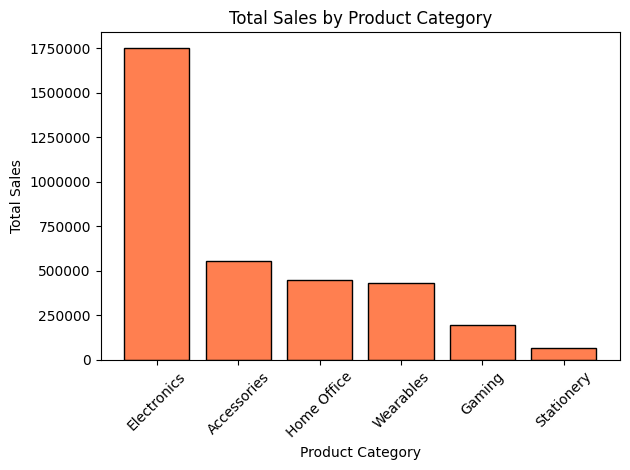

In [82]:
plt.bar(category_sales.index, category_sales.values, color='coral', edgecolor='Black')
plt.xlabel('Product Category')
plt.ylabel('Total Sales')
plt.title('Total Sales by Product Category')

plt.xticks(rotation=45)
plt.ticklabel_format(axis='y', style='plain')
plt.tight_layout()
plt.show()

- Electronics generated the highest total sales (approximately 1.75 million), accounting for around 50.8% of total recorded sales.

- Accessories ranked second, while Home Office and Wearables recorded similar sales levels.

- Gaming and Stationery contributed considerably less, with Stationery recording the lowest sales.

###2. Top 10 Products by Sales

This chart compares the top 10 products based on total recorded sales.

In [83]:
top_10_products= product_sales.sort_values(ascending=False).head(10)

fig= px.bar(
    x=top_10_products.values,
    y=top_10_products.index,
    orientation='h',
    labels={'x':'Total Sales', 'y': 'Product'},
    title='Top 10 Products by Sales')

fig.show()


- Headphones recorded the highest total sales (333,531), followed by Office Chair (329,292) and Tablet (292,344).
- The top 10 products include a mix of electronics, accessories, gaming and home-office products, indicating that sales are spread across several product types.

###3. Quantity Sold by Category

This bar chart compares the total quantity sold across product categories to identify which categories have the highest sales volume.

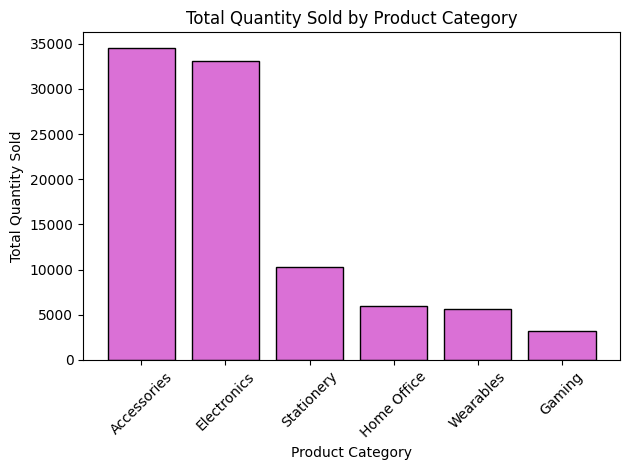

In [84]:
category_quantity = df_clean.groupby('Category')['Quantity'].sum()
category_quantity = category_quantity.sort_values(ascending=False)

plt.bar(category_quantity.index, category_quantity.values,
        color='orchid', edgecolor='black')

plt.xlabel('Product Category')
plt.ylabel('Total Quantity Sold')
plt.title('Total Quantity Sold by Product Category')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

- Accessories has the highest quantity sold, followed by Electronics.
- Electronics generates the highest sales value, while Accessories sells the most units, suggesting differences in product prices across categories.

###4. Monthly Sales Trends

This line chart compares monthly recorded sales across 2024, 2025 and 2026 to examine changes in sales over time.

In [85]:
month_names=['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']

fig= px.line(
    monthly_comparison,
    x=month_names,
    y=monthly_comparison.columns,
    markers=True,
    title='Monthly Sales Trends by Year',
    labels={'x': 'Month',
            'value': 'Total Sales',
            'variable': 'Year'})

fig.show()


- Monthly sales fluctuated throughout 2024 and 2025, with the highest monthly sales recorded in May 2025 (130,625).
- January 2026 recorded sales of 130,550, the highest January value across the three years.
- Sales from February to June 2026 were lower than in the corresponding months of 2024 and 2025. However, 2026 data covers only January to June, so full-year comparisons are not possible.

###5. Customer Age Distribution

This histogram shows the distribution of customer ages in the dataset.

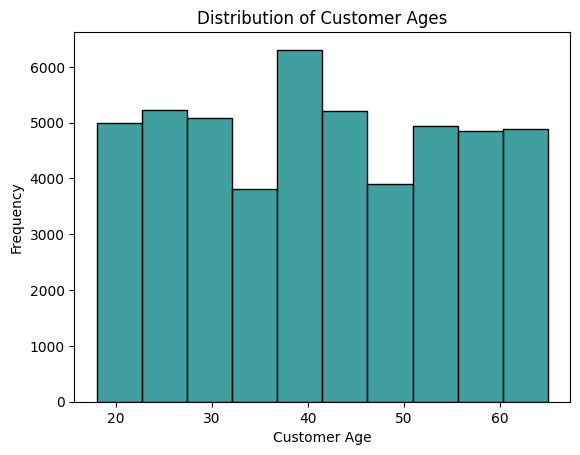

In [86]:
sns.histplot(data=df_clean, x='Age', bins=10, color='teal')
plt.xlabel('Customer Age')
plt.ylabel('Frequency')
plt.title('Distribution of Customer Ages')
plt.show()

- Customer ages range from 18 to 65, with records distributed across the age range.

- The highest frequency occurs around ages 37–42, while lower frequencies appear around ages 32–37 and 47–52.

- The distribution is relatively spread out, with no single narrow age range dominating the dataset.

- The histogram represents transaction records rather than unique customers, as customers may appear in multiple transactions.

###6. Total Sales by Customer Segment

This bar chart compares total sales across customer segments to identify which segment contributes the most to recorded sales.

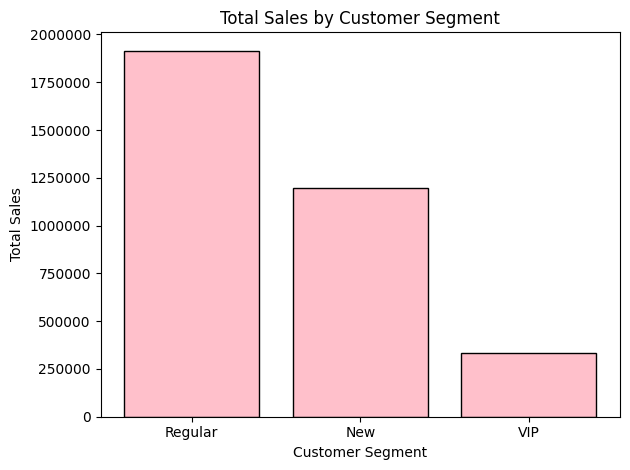

In [87]:
plt.bar(segment_sales.index, segment_sales.values, color='pink', edgecolor='black')

plt.xlabel('Customer Segment')
plt.ylabel('Total Sales')
plt.title('Total Sales by Customer Segment')
plt.ticklabel_format(axis='y', style='plain')
plt.tight_layout()
plt.show()

###7. Distribution of Sales

This box plot examines the median sales value, the spread of sales values, and the presence of unusually high or low values in the dataset.

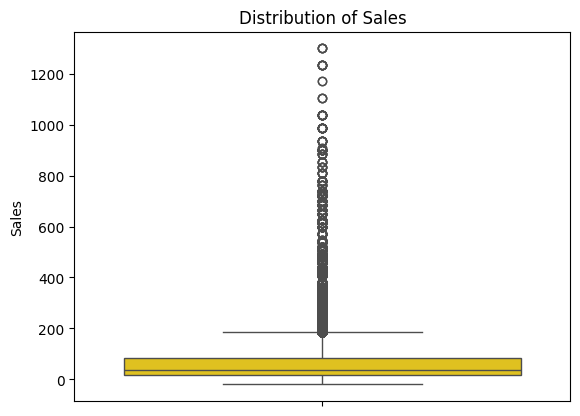

In [88]:
sns.boxplot(data=df_clean, y='Sales', color='gold')

plt.ylabel('Sales')
plt.title('Distribution of Sales')
plt.ticklabel_format(axis='y', style='plain')

plt.show()

- Concentration of sales values: Most transactions have relatively low sales values, with the median substantially below the upper end of the distribution. This suggests that typical transactions contribute less sales value than a smaller number of high-value transactions.
- Presence of potential outliers: Numerous points appear above the upper whisker, with some sales values exceeding 1,200. These represent transactions with unusually high sales values compared with the majority of records.
- Right-skewed distribution: The long upper tail indicates a positively skewed distribution. A small proportion of transactions may contribute disproportionately to total recorded sales, although the box plot alone cannot establish their exact contribution.
- Business implication: Investigating these high-value transactions could help identify products, order quantities, or purchasing patterns associated with higher sales.

###8. Relationship Between Unit Price and Sales

This scatter plot examines how unit prices relate to sales values across transactions, helping identify patterns between product prices and recorded sales.

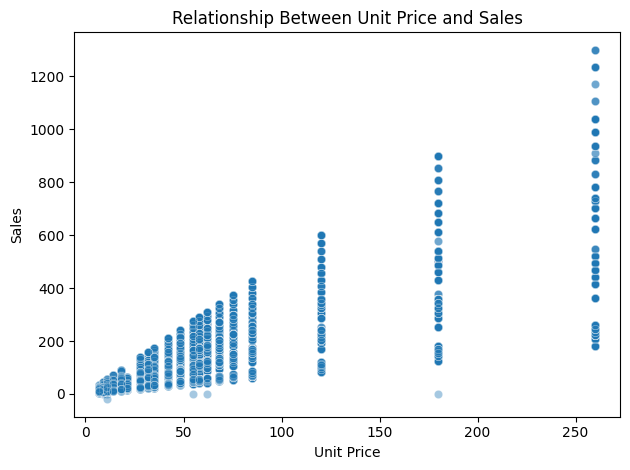

In [89]:
sns.scatterplot(data=df_clean, x='UnitPrice', y='Sales', alpha=0.4)

plt.xlabel('Unit Price')
plt.ylabel('Sales')
plt.title('Relationship Between Unit Price and Sales')
plt.tight_layout()
plt.show()

- Positive relationship: Sales values generally increase as unit prices increase.
- Greater variation at higher prices: Higher-priced products show a wider range of sales values.
- Potential unusual values: A few points fall around zero or below, which may warrant checking against the transaction records.

###9. Order Status by Customer Segment

Seaborn grouped bar chart compares order statuses across customer segments to identify differences in completed, cancelled, and returned transactions.

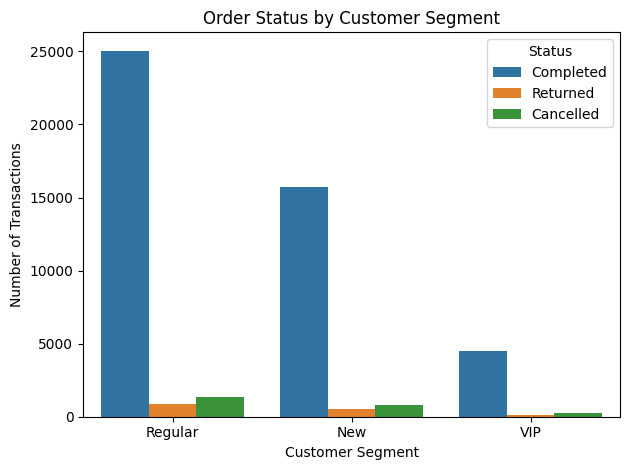

In [90]:
sns.countplot(data=df_clean, x='CustomerSegment', hue='Status')

plt.xlabel('Customer Segment')
plt.ylabel('Number of Transactions')
plt.title('Order Status by Customer Segment')
plt.tight_layout()
plt.show()

- Regular customers have the highest number of transactions, followed by New customers and then VIP customers. This is consistent with the larger number of transactions from Regular customers in the dataset.



- Completed transactions are the most common status across all three segments, showing that most recorded transactions were completed.



- Regular customers have the highest numbers of returns and cancellations, while VIP customers have the lowest numbers. However, this may be because Regular customers have more transactions overall.

###10. Distribution of Payment Methods

This doughnut chart compares the number of transactions made using different payment methods, highlighting the most and least frequently used options.

In [91]:
payment_counts= df_clean['PaymentMethod'].value_counts().reset_index()
payment_counts.columns= ['PaymentMethod', 'Transactions']

fig= px.pie(payment_counts, names='PaymentMethod', values='Transactions',
            title='Distribution of Payment Methods', hole=0.4)

fig.show()

- Gateway is the most commonly used payment method, accounting for 48.6% of transactions (approximately 23,891 transactions).



- CardToCard is the second most popular option, representing 23.9% of transactions (11,738 transactions).



- Wallet accounts for 17.6% of transactions, while Cash is the least used payment method at 10%.



- Digital payment methods dominate the chart, with Gateway, CardToCard, and Wallet together accounting for approximately 90% of transactions. This suggests that customers strongly prefer these payment options over cash.

###11. Correlation Between Numerical Variables

This heatmap shows the relationships between numerical variables in the dataset, helping identify which variables are positively or negatively related.

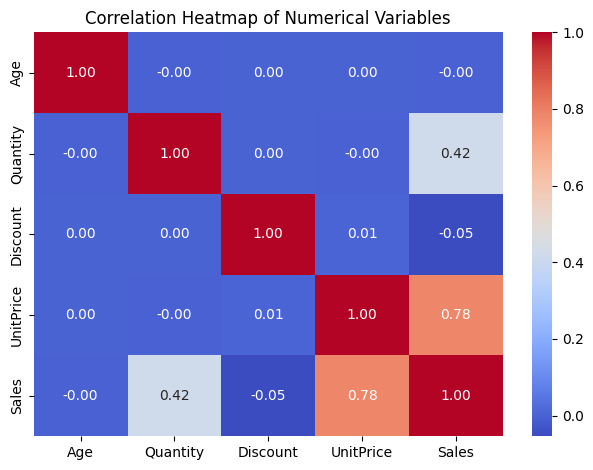

In [92]:
correlation_matrix= df_clean[['Age', 'Quantity', 'Discount', 'UnitPrice', 'Sales']].corr()

sns.heatmap(correlation_matrix, annot= True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap of Numerical Variables')
plt.tight_layout()
plt.show()

- UnitPrice and Sales (0.78): These variables have a strong positive relationship. Transactions involving higher-priced products generally tend to have higher sales values.



- Quantity and Sales (0.42): These variables have a moderate positive relationship. Transactions with larger quantities generally tend to have higher sales values.



- Discount and Sales (-0.05): This value is very close to zero, indicating almost no linear relationship between discount and sales in this dataset.



- Age and Sales (approximately 0.00): There is almost no linear relationship between customer age and sales values. Age also has almost no linear relationship with the other numerical variables.

###12. Sales by City

This bar chart compares total sales across cities to identify the highest- and lowest-performing geographical markets.

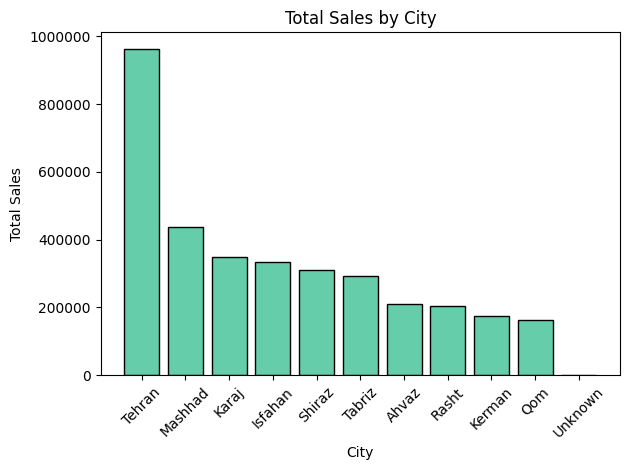

In [93]:
plt.bar(city_sales.sort_values(ascending=False).index,
        city_sales.sort_values(ascending=False).values,
        color='mediumaquamarine', edgecolor='black')

plt.xlabel('City')
plt.ylabel('Total Sales')
plt.title('Total Sales by City')
plt.xticks(rotation=45)
plt.ticklabel_format(axis='y', style='plain')
plt.tight_layout()
plt.show()

- Tehran leads in sales with 963,320, more than twice the total recorded for Mashhad (438,089).
- Qom has the lowest sales among the named cities, at 162,760.



